# PyTorch

## __Tensors__

Одно из основных понятий в PyTorch - это __Tenosor__.

https://pytorch.org/docs/master/tensors.html

__Tensor__ - это такой же массив, как и в __numpy.array__, размерность и тип данных которого мы можем задать. Tensor в отличие от numpy.array может вычисляться на __GPU__.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [2]:
N = 100
D_in = 50

dtype = torch.float
device = torch.device("cpu")
# device = torch.device("cuda:0")  # uncomment this to run on GPU

x = np.random.randn(N, D_in)
x_torch = torch.randn(N, D_in, device=device, dtype=dtype)

In [3]:
x

array([[-0.47597218,  0.62054552, -1.18792577, ..., -0.05816061,
        -0.34160902,  1.79597118],
       [ 0.11709668, -1.19492087,  1.01677071, ...,  0.14355773,
        -0.27726136, -0.41751941],
       [-2.03613547,  1.09254626, -0.43731856, ..., -0.42109564,
         0.5619146 ,  0.40184244],
       ...,
       [ 0.01791303,  0.3396711 , -0.74643492, ...,  0.30461218,
        -0.42130645,  1.30342874],
       [ 0.59157434, -0.12038846, -0.30085507, ..., -0.22560674,
        -1.43793064, -1.28374923],
       [ 0.14991205,  0.20185618, -1.2760204 , ...,  0.66442405,
        -0.22848929,  0.4870539 ]])

In [4]:
x_torch

tensor([[ 1.1398,  1.2157,  0.0075,  ..., -0.1783, -0.8899, -0.2199],
        [ 0.3216, -0.0864,  0.2992,  ...,  1.0556,  0.1805,  0.8938],
        [ 0.6117, -0.8358,  0.6415,  ..., -0.0226,  0.0663,  0.2802],
        ...,
        [ 0.9308,  1.0508,  0.6200,  ...,  0.8865,  0.5998, -2.7662],
        [-1.0567, -0.2228, -1.2477,  ..., -0.0155,  1.2954, -0.1298],
        [-0.5160, -0.2237, -0.2347,  ...,  1.8551, -0.7146, -0.8042]])

In [5]:
x_torch = torch.Tensor(np.ones((N, D_in)))
x_torch

tensor([[1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        ...,
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.]])

In [6]:
x_torch = torch.FloatTensor([1, 2, 3])
x_torch

tensor([1., 2., 3.])

In [7]:
x1 = torch.IntTensor([1, 2, 3])
x2 = torch.FloatTensor([3, 4, 5])

В PyTorch можно найти много операций, которые похожи на то, что есть в numpy:
- `torch.add` (`np.add`) -> сложение тензоров (поэлементное)
- `torch.sub` (`np.subtract`) -> вычитание (поэлементное)
- `torch.mul` (`np.multiply`) -> умнажение скаляров / матриц (поэлементное)
- `torch.mm` (`np.matmul`) -> перемножение матриц
- `torch.ones` (`np.ones`) -> создание тензора из единиц
- `torch.reshape` (`np.reshape`) -> изменения порядка элементов в тензоре, **не путать с транспонированием**.

In [8]:
# Давайте попробуем вышепересчисленные операции
x1 = torch.FloatTensor([[1, 2, 3], [4, 5, 6]])
x2 = torch.FloatTensor([[7, 8], [9, 1], [2, 3]])
out = torch.mm(x1, x2)
out

tensor([[31., 19.],
        [85., 55.]])

## Dynamic Computational Graph

После того, как были реализованы архитектура модели и весь процес обучения и валидация сети, при запуске кода в PyTorch происходят следующие этапы:

1. Строится вычислительный граф (направленный ациклический граф), где каждый узел -- это тензор, а ребро, ведущее к дргуому узлу, это выполнение операции над данным тензором, которое ведет к результату - другому тензору.

<img src="https://beebom.com/wp-content/uploads/2016/07/Tensor-bb-tensor-flowing.jpg" alt="Drawing" style="height: 100px;"/>

Реализуем двухслойную сеть для задачи регрессии. И граф для такой архитектуры бдует выглядить следующим образом:

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/RegGraph.png?raw=1" alt="Drawing" />

In [15]:
BATCH_SIZE = 64
INPUT_SIZE = 1
HIDDEN_SIZE = 4
OUTPUT_SIZE = 1

In [16]:
# Create random input and output data
x = np.arange(-10, 10, 0.1).reshape(-1, 1)
y = x**2 * np.sin(x).reshape(-1, 1)

x = torch.FloatTensor(x)
y = torch.FloatTensor(y)

# Randomly initialize weights
w1 = torch.randn(INPUT_SIZE, HIDDEN_SIZE, device=device, dtype=dtype)
w2 = torch.randn(HIDDEN_SIZE, OUTPUT_SIZE, device=device, dtype=dtype)

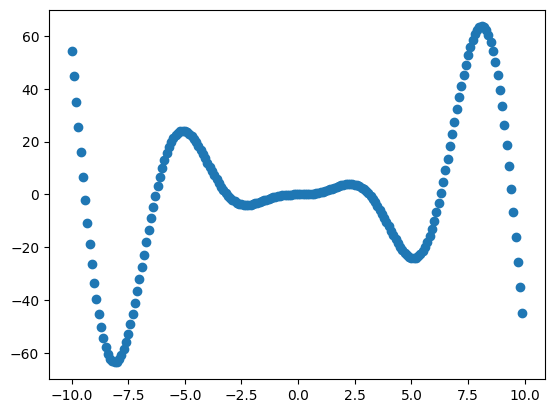

In [11]:
plt.scatter(x, y)

In [20]:
learning_rate = 1e-6
for t in range(500):
    # Forward pass: compute predicted y
    h1 = x.mm(w1)
    h1_relu = h1.clamp(min=0.0)
    y_pred = h1_relu.mm(w2)

    # Compute and print loss
    loss = (y_pred - y).pow(2).mean().item()
    if t % 100 == 0:
        print(t, loss)

    # Backward pass
    # 1) dL/dy_pred
    dL_dy_pred = 2 * (y_pred - y) / y.numel()
    # 2) слой w2
    grad_w2 = h1_relu.T @ dL_dy_pred
    dL_dh1_relu = dL_dy_pred @ w2.T
    # 3) ReLU
    dL_dh1 = dL_dh1_relu * (h1 > 0).float()
    # 4) слой w1
    grad_w1 = x.T @ dL_dh1

    # Update weights using gradient descent
    w1 -= learning_rate * grad_w1
    w2 -= learning_rate * grad_w2

0 673.6149291992188
100 673.177978515625
200 672.7462768554688
300 672.3197021484375
400 671.8981323242188


In [21]:
loss

671.485595703125

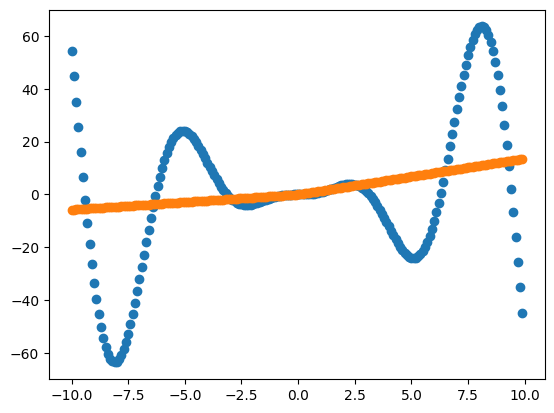

In [22]:
plt.scatter(x, y)
plt.scatter(x, y_pred)

## Autograd

2. Еще одно фундаментальное понятие и важный элемент при построении графа -- это __Autograd__ -- автоматическое дифференцирование.

Для того чтобы с помощью стохастического градиентного спуска обновить обучаемые параметры сети, нужно посчитать градиенты. И как известно, обновление весов, которые учавтсвуют в нескольких операциях, происходит по `правилу дифференцирования сложной функции` (цепное правило или __chain rule__).

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/RegChainRule.png?raw=1" alt="Drawing" />

То есть (1) вычислительный граф позволяет определить последовательность операций, а (2) автоматическое дифференцирование посчитать нужные градиенты.

Если бы `Autograd` не было, то тогда backprop надо было бы реализовывать самим, и как это бы выглядело?

Рассмотрим на примере, как посчиать градиенты для весов из входного слоя, где входной вектора `X` состоит из 3-х компонент. А входной слой вторую размерность имеет равной 2.

После чего это идет в `ReLU`, но для простоты опустим на время ее, и посмотрим как дальше это идет по сети.

Ниже написано, как это все вычисляется и приводит нас к значению целевой функции для одного наблюдения

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/1.png?raw=1" alt="1" style="width: 600px;"/>

Тогда, чтобы посчитать градиент по первому элементу из обучаемой матрицы на первом слое, необходимо взять производоную у сложной функции. А этот как раз делается по `chain rule`: сначала берем у внешней, потом спускаемся на уровень ниже, и так пока не додйдем до то функции, после которой эта перменная уже нигде не участвует:

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/2.png?raw=1" alt="2" style="width: 400px;"/>

Перепишем это все в матричном виде, то есть сделаем аналог вида матрицы весов из первого слоя, но там уже будут её градиенты, котоыре будут нужны чтобы как раз обновить эти веса:

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/3.jpg?raw=1" alt="3" style="width: 600px;"/>

Как видно, здесь можно вектор X вынести, то есть разделить на две матрицы:

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/4.jpg?raw=1" alt="4" style="width: 500px;"/>

То есть уже видно, что будем траспонировать входной вектор(матрицу). Но надо понимать, что в реальности у нас не одно наблюдение в батче, а несколько, тогда запись немного изменит свой вид:

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/5.jpg?raw=1" alt="5" style="width: 500px;"/>

Теперь мы видим, как на самом деле вычисляется вот те самые частные производные для вектора X, то есть видно, как математически это можно записать, а именно:

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/6.jpg?raw=1" alt="6" style="width: 500px;"/>

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/7.jpg?raw=1" alt="7" style="width: 500px;"/>

Уже можно реализовать. Понятно, что транспонируется, что нет, и что на что умножается.

Но помним про ReLU. Для простоты опустили, но теперь её учесть будет легче.

Так как после первого слоя идет ReLU, а значит, занулились те выходы первого слоя, которые были __меньше__ нуля. Получается, что во второй слой не все дошло, тогда нужно обнулить, что занулил ReLU.

Что занулил ReLU, мы можем выяснить при `forward pass`, а где именно поставить нули, то надо уже смотреть относительно `backward propagation`, на том выходе, где последний раз участвовал выход после ReLU, то есть:

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/8.jpg?raw=1" alt="8" style="width: 600px;"/>

Теперь реализуем эти формулы на PyTorch:

In [13]:
# 1) dL/dy_pred
dL_dy_pred = 2 * (y_pred - y) / y.numel()
# 2) слой w2
grad_w2 = h1_relu.T @ dL_dy_pred
dL_dh1_relu = dL_dy_pred @ w2.T
# 3) ReLU
dL_dh1 = dL_dh1_relu * (h1 > 0).float()
# 4) слой w1
grad_w1 = x.T @ dL_dh1

# Update weights using gradient descent
w1 -= learning_rate * grad_w1
w2 -= learning_rate * grad_w2

Благодаря `Autograd` реализацию `chain rule` можно избежать, так как для более сложных нейронных сетей вручную такое реализовать сложно, при этом сделать это эффективным.

Для того чтобы PyTorch понял, за какими переменными надо "следить", то есть указать, что именно "эти" переменные являются обучаемыми, необходимо при создании тензора в качестве аттрибута указать __requires_grad=True__:

In [25]:
w1 = torch.randn(INPUT_SIZE, HIDDEN_SIZE, device=device, dtype=dtype, requires_grad=True)
w2 = torch.randn(HIDDEN_SIZE, OUTPUT_SIZE, device=device, dtype=dtype, requires_grad=True)

In [27]:
learning_rate = 1e-6
for t in range(50_000):
    # Forward pass: compute predicted y
    h1 = x.mm(w1)
    h_relu = torch.relu(h1)
    y_pred = h_relu.mm(w2)

    loss = (y_pred - y).pow(2).mean()
    if t % 1000 == 0:
        print(t, loss.item())

    # Теперь подсчет градиентов для весов происходит при вызове backward
    loss.backward()

    # Обновляем значение весов, но укзаываем, чтобы PyTorch не считал эту операцию,
    # которая бы учавствовала бы при подсчете градиентов в chain rule
    with torch.no_grad():
        w1 -= learning_rate * w1.grad
        w2 -= learning_rate * w2.grad

        # Теперь обнуляем значение градиентов, чтобы на следующем шаге
        # они не учитывались при подсчете новых градиентов,
        # иначе произойдет суммирвоание старых и новых градиентов
        w1.grad.zero_()
        w2.grad.zero_()

0 706.0060424804688
1000 706.0060424804688
2000 706.0060424804688
3000 706.0060424804688
4000 706.0060424804688
5000 706.0060424804688
6000 706.0060424804688
7000 706.0060424804688
8000 706.0060424804688
9000 706.0060424804688
10000 706.0060424804688
11000 706.0060424804688
12000 706.0060424804688
13000 706.0060424804688
14000 706.0060424804688
15000 706.0060424804688
16000 706.0060424804688
17000 706.0060424804688
18000 706.0060424804688
19000 706.0060424804688
20000 706.0060424804688
21000 706.0060424804688
22000 706.0060424804688
23000 706.0060424804688
24000 706.0060424804688
25000 706.0060424804688
26000 706.0060424804688
27000 706.0060424804688
28000 706.0060424804688
29000 706.0060424804688
30000 706.0060424804688
31000 706.0060424804688
32000 706.0060424804688
33000 706.0060424804688
34000 706.0060424804688
35000 706.0060424804688
36000 706.0060424804688
37000 706.0060424804688
38000 706.0060424804688
39000 706.0060424804688
40000 706.0060424804688
41000 706.0060424804688
42000

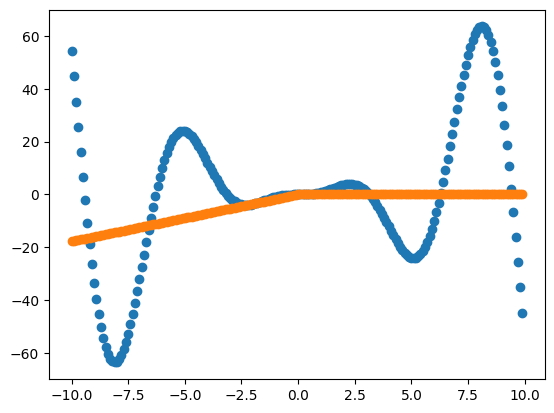

In [28]:
plt.scatter(x, y)
plt.scatter(x, y_pred.detach().numpy())

Осталось еще не вручную обновлять веса, а использовать адаптивные методы градинетного спсука. Для этого нужно использовать модуль __optim__. А помимо оптимайзера, еще можно использовать готовые целевые функции из модлуя __nn__.

In [29]:
w1 = torch.randn(INPUT_SIZE, HIDDEN_SIZE, device=device, dtype=dtype, requires_grad=True)
w2 = torch.randn(HIDDEN_SIZE, OUTPUT_SIZE, device=device, dtype=dtype, requires_grad=True)

In [32]:
import torch.optim as optim

loss_fn = torch.nn.MSELoss(reduction="mean")

learning_rate = 1e-3
optimizer = torch.optim.Adam([w1, w2], lr=learning_rate)

for t in range(50_000):
    optimizer.zero_grad()

    h1 = x.mm(w1)
    h_relu = torch.relu(h1)
    y_pred = h_relu.mm(w2)

    loss = loss_fn(y_pred, y)
    if t % 1000 == 0:
        print(t, loss.item())

    loss.backward()

    optimizer.step()

0 640.6456298828125
1000 640.6456298828125
2000 640.6455688476562
3000 640.6455688476562
4000 640.6455688476562
5000 640.6455688476562
6000 640.6455688476562
7000 640.6456298828125
8000 640.6455688476562
9000 640.6456298828125
10000 640.6455688476562
11000 640.6455688476562
12000 640.6455688476562
13000 640.6455688476562
14000 640.6455688476562
15000 640.6456298828125
16000 640.6456298828125
17000 640.6455688476562
18000 640.6455688476562
19000 640.6455688476562
20000 640.6456298828125
21000 640.6455688476562
22000 640.6455688476562
23000 640.6455688476562
24000 640.6455688476562
25000 640.6456298828125
26000 640.6455688476562
27000 640.6455688476562
28000 640.6456298828125
29000 640.6455688476562
30000 640.6455688476562
31000 640.6455688476562
32000 640.6455688476562
33000 640.6455688476562
34000 640.6455688476562
35000 640.6455688476562
36000 640.6455688476562
37000 640.6455688476562
38000 640.6455688476562
39000 640.6455688476562
40000 640.6455688476562
41000 640.6455688476562
42000

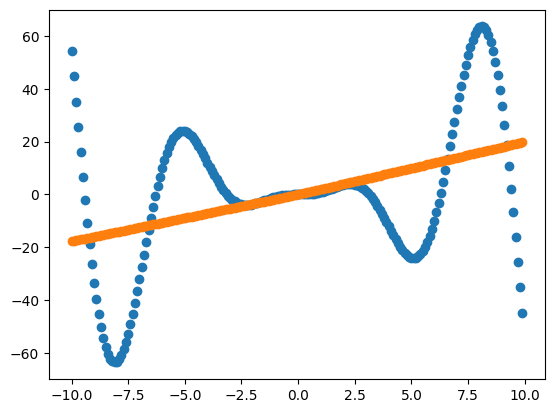

In [33]:
plt.scatter(x, y)
plt.scatter(x, y_pred.detach().numpy())

После того, как мы сделали backward, в этот момент посчитались градиенты и граф уничтожился, то есть стёрлись все пути, которые связывали тензоры между собой. Это значит, что еще раз backward сделать не поулчится, будет ошибка. Но если вдруг нужно считать градиенты еще раз, то нужно при вызове backward задать `retain_graph=True`.

Еще важный аттрибут, который есть у Tensor -- это `grad_fn`. В этом аттрибуте указывается та функция, посредством которой был создан этот тензор. Так PyTorch понимает, как именно считать по нему градиент.

In [20]:
y_pred.grad_fn

Также можно контролировать, должны ли градиенты течь или нет.

In [21]:
x = torch.tensor([1.0], requires_grad=True)
with torch.no_grad():
    with torch.enable_grad():
        y = x * 2
y.requires_grad

True

## Почему Backprop надо понимать

1. Backprop позволяет понимать, как те или иные операции, сложные конструкции в сети влияют на обнолвение весов.
Почему лучше сделать конкатенацию тензоров, а не поэлементное сложение. Для этого нужно посмотреть на backprop, как будут обновляться веса.

2. Даже на таком маленьком пример двуслойной MLP можно уже увидеть, когда `ReLU`, как функция активация, не очень хорошо применять. Если разреженные данные, то получить на выходе много нулей вероятнее, чем при использовании `LeakyReLU`, то есть градиенты будут нулевыми и веса никак не будут обновляться => сеть не обучается!

3. В архитектуре могут встречаться недифференцируемые операции, и первое - это нужно понять, потому что при обучении сети это может быть не сразу заметно, просто качество модели будет плохое, и точность хорошую не поулчится достичь.

Например, в одной из статей было предложено в качестве механизма внимания применить распределение Бернулли, которое умножается на выход промежуточного слоя сети. И эта опреация недифференцируема, нужно реализовывать backprop самим, тем самым обеспечить корректное протекание градиентов.


<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/Bernoulli.png?raw=1" alt="8" style="width: 600px;"/>

Так же любая статья, которая предлагет новую целевую функцию для той или иной задачи, там всегда будут представлены градиенты, чтобы было понимание, как это влияет на обновление весов. Не просто так !

<img src="https://github.com/RiskModellingResearch/RiskManagementDL_Autumn21/blob/main/week03/images/BernoulliBackProp.png?raw=1" alt="8" style="width: 600px;"/>

## nn.Module

В предыдущем примере архитектуру сети создавали используя последовательной способ объявления слоев сети -- `nn.Sequential`.

Но еще можно это сделать более гибким подходом:

In [34]:
from torch import nn


class TwoLayerNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        """
        TwoLayerNet наследуется от nn.Module и тем самым полчаем возможность
        переопределять методы класса.
        В конструктуре создаем слои (обучаемые веса) и другие нужные перменные/функции,
        которые нужны для модели
        """
        super(TwoLayerNet, self).__init__()
        self.linear1 = torch.nn.Linear(input_size, hidden_size, bias=False)
        self.linear2 = torch.nn.Linear(hidden_size, output_size, bias=False)

    def forward(self, x):
        """
        Метод forward отвечает за прямое распростронение модели,
        поэтому данный метод нужно переопределять обязательно,
        чтобы задать логику прямого распростронения.
        Именно в этот момент начинает строится динамический граф
        """
        h_relu = torch.relu(self.linear1(x))
        y_pred = self.linear2(h_relu)

        return y_pred

In [35]:
batch_size = 64
input_size = 1
hidden_size = 4
output_size = 1

model = TwoLayerNet(input_size, hidden_size, output_size)

loss_fn = torch.nn.MSELoss(reduction="mean")
optimizer = torch.optim.SGD(model.parameters(), lr=1e-4)

for t in range(50_000):
    y_pred = model(x)

    loss = loss_fn(y_pred, y)
    if t % 1000 == 0:
        print(t, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 747.674072265625
1000 693.9777221679688
2000 693.9777221679688
3000 693.9777221679688
4000 693.9777221679688
5000 693.9777221679688
6000 693.9777221679688
7000 693.9777221679688
8000 693.9777221679688
9000 693.9777221679688
10000 693.9777221679688
11000 693.9777221679688
12000 693.9777221679688
13000 693.9777221679688
14000 693.9777221679688
15000 693.9777221679688
16000 693.9777221679688
17000 693.9777221679688
18000 693.9777221679688
19000 693.9777221679688
20000 693.9777221679688
21000 693.9777221679688
22000 693.9777221679688
23000 693.9777221679688
24000 693.9777221679688
25000 693.9777221679688
26000 693.9777221679688
27000 693.9777221679688
28000 693.9777221679688
29000 693.9777221679688
30000 693.9777221679688
31000 693.9777221679688
32000 693.9777221679688
33000 693.9777221679688
34000 693.9777221679688
35000 693.9777221679688
36000 693.9777221679688
37000 693.9777221679688
38000 693.9777221679688
39000 693.9777221679688
40000 693.9777221679688
41000 693.9777221679688
42000 

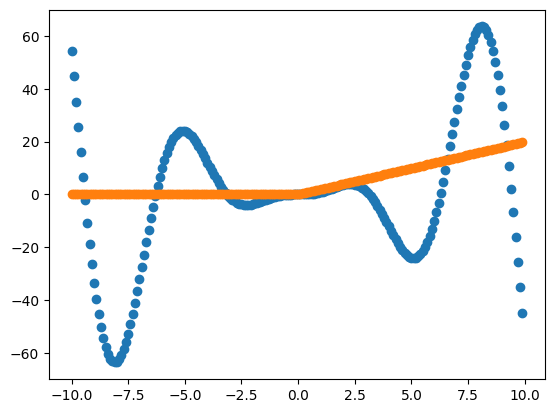

In [36]:
plt.scatter(x, y)
plt.scatter(x, y_pred.detach().numpy())